# A/B Test Read-out: should we ship the new landing page?

A complete experiment read-out: data checks, power analysis, the result with a confidence interval, a segment check, and a decision taken from **rules written before reading the result**.

Repo: [github.com/tima-chan/A-B-Test-Website](https://github.com/tima-chan/A-B-Test-Website)

| Pre-set rule | Setting |
|---|---|
| Primary metric | User conversion (first exposure only) |
| Minimum worthwhile lift | **+0.5 pp** |
| α / power | 0.05 two-sided / 80% |
| Validity | Sample-ratio mismatch χ² p < 0.001 ⇒ invalid |
| Ship | CI > 0 and lift ≥ +0.5 pp · **Don't ship** if CI upper bound < +0.5 pp and the test is powered for it |

In [1]:
from pathlib import Path
import pandas as pd
# Use the attached Kaggle dataset if present, otherwise the copy in the GitHub repo
hits = list(Path('/kaggle/input').rglob('ab_data.csv')) if Path('/kaggle/input').exists() else []
if hits:
    AB, COUNTRIES = hits[0], next(Path('/kaggle/input').rglob('countries.csv'))
elif Path('ab_data.csv').exists():
    AB, COUNTRIES = 'ab_data.csv', 'countries.csv'
else:
    RAW = 'https://raw.githubusercontent.com/tima-chan/A-B-Test-Website/master/'
    AB, COUNTRIES = RAW + 'ab_data.csv', RAW + 'countries.csv'
print(AB)

https://raw.githubusercontent.com/tima-chan/A-B-Test-Website/master/ab_data.csv


## Analysis functions

In [2]:
"""Experiment read-out for the landing-page test: data checks, power analysis,
result with confidence interval, segment check, and a decision from pre-set rules.

    python abtest.py                 # prints the read-out and writes figures/
"""
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize


# ---------------------------------------------------------------- decision rules
@dataclass(frozen=True)
class Rules:
    """Written before looking at the result. See DECISION_RULES.md."""
    alpha: float = 0.05            # two-sided
    power: float = 0.80
    mde_abs: float = 0.005         # smallest lift worth shipping: +0.5 pp conversion
    srm_alpha: float = 0.001       # sample-ratio-mismatch alarm


RULES = Rules()


# ---------------------------------------------------------------- data
def load(path="ab_data.csv", countries="countries.csv") -> tuple[pd.DataFrame, dict]:
    raw = pd.read_csv(path, parse_dates=["timestamp"])
    qa = {"rows": len(raw)}
    misaligned = (raw.group == "treatment") != (raw.landing_page == "new_page")
    qa["misaligned_rows"] = int(misaligned.sum())
    df = raw[~misaligned]
    qa["duplicate_users"] = int(df.user_id.duplicated().sum())
    df = df.drop_duplicates("user_id", keep="first")
    df = df.merge(pd.read_csv(countries), on="user_id", how="left")
    df["treated"] = (df.group == "treatment").astype(int)
    qa["users"] = len(df)
    return df.reset_index(drop=True), qa


# ---------------------------------------------------------------- checks
def srm_check(df) -> float:
    """Chi-square test that users split 50/50. A tiny p-value means broken assignment."""
    counts = df.group.value_counts().reindex(["control", "treatment"]).to_numpy()
    return stats.chisquare(counts).pvalue


def required_n_per_arm(p_base, mde_abs, rules=RULES) -> int:
    es = proportion_effectsize(p_base + mde_abs, p_base)
    return int(np.ceil(NormalIndPower().solve_power(es, alpha=rules.alpha, power=rules.power)))


def achieved_mde(p_base, n_per_arm, rules=RULES) -> float:
    """Smallest absolute lift this sample could detect with the chosen power."""
    es = NormalIndPower().solve_power(nobs1=n_per_arm, alpha=rules.alpha, power=rules.power)
    # invert Cohen's h: h = 2·asin(√p1) − 2·asin(√p0)
    p1 = np.sin(np.arcsin(np.sqrt(p_base)) + es / 2) ** 2
    return p1 - p_base


# ---------------------------------------------------------------- result
def diff_in_proportions(df, alpha=RULES.alpha):
    g = df.groupby("group").converted.agg(["sum", "size"])
    xc, nc = g.loc["control"]
    xt, nt = g.loc["treatment"]
    pc, pt = xc / nc, xt / nt
    diff = pt - pc
    se_unpooled = np.sqrt(pc * (1 - pc) / nc + pt * (1 - pt) / nt)
    z_crit = stats.norm.ppf(1 - alpha / 2)
    p_pool = (xc + xt) / (nc + nt)
    z = diff / np.sqrt(p_pool * (1 - p_pool) * (1 / nc + 1 / nt))
    return {
        "control_rate": pc, "treatment_rate": pt, "diff": diff,
        "rel_lift": diff / pc,
        "ci": (diff - z_crit * se_unpooled, diff + z_crit * se_unpooled),
        "p_value": 2 * stats.norm.sf(abs(z)), "n_control": int(nc), "n_treatment": int(nt),
    }


def prob_treatment_better(df, draws=200_000, seed=0) -> float:
    """Beta(1,1) prior; share of posterior draws where treatment converts more."""
    rng = np.random.default_rng(seed)
    g = df.groupby("group").converted.agg(["sum", "size"])
    post = {k: rng.beta(1 + g.loc[k, "sum"], 1 + g.loc[k, "size"] - g.loc[k, "sum"], draws)
            for k in ("control", "treatment")}
    return float((post["treatment"] > post["control"]).mean())


def country_interaction(df) -> pd.DataFrame:
    """Does the effect differ by country? Logistic model with treatment × country."""
    m = smf.logit("converted ~ treated * C(country, Treatment('US'))", data=df).fit(disp=0)
    out = pd.DataFrame({"coef": m.params, "p_value": m.pvalues})
    return out[out.index.str.contains(":")]


def decide(res, mde_hat, srm_p, rules=RULES) -> str:
    lo, hi = res["ci"]
    if srm_p < rules.srm_alpha:
        return "INVALID: sample-ratio mismatch. Fix assignment before reading results."
    if lo > 0 and res["diff"] >= rules.mde_abs:
        return "SHIP: lift is significant and at least the minimum worthwhile effect."
    if lo > 0:
        return "ITERATE: significant but below the minimum worthwhile effect."
    if hi < rules.mde_abs:
        if mde_hat <= rules.mde_abs:
            return ("DO NOT SHIP: the test was powered to detect +0.5 pp and the CI rules it out. "
                    "Running longer would not change the decision.")
        return "INCONCLUSIVE: underpowered. Extend to the required sample size."
    return "INCONCLUSIVE: CI still includes a worthwhile lift. Extend to the required sample size."


# ---------------------------------------------------------------- figures
BLUE, ORANGE, TEXT, MUTED, GRID = "#257de0", "#f47230", "#191919", "#666666", "#e6e6e6"
plt.rcParams.update({
    "font.size": 10, "text.color": TEXT, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "figure.dpi": 150,
})


def fig_cumulative(df, path):
    """Cumulative lift with 95% CI by day: shows why peeking early misleads."""
    d = df.sort_values("timestamp").assign(day=lambda x: x.timestamp.dt.normalize())
    rows = []
    for day in sorted(d.day.unique())[1:]:
        r = diff_in_proportions(d[d.day <= day])
        rows.append((day, r["diff"] * 100, r["ci"][0] * 100, r["ci"][1] * 100))
    c = pd.DataFrame(rows, columns=["day", "diff", "lo", "hi"])
    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.fill_between(c.day, c.lo, c.hi, color=BLUE, alpha=0.18, linewidth=0, label="95% CI")
    ax.plot(c.day, c["diff"], color=BLUE, lw=2, label="Cumulative lift")
    ax.axhline(0, color=MUTED, lw=1)
    ax.axhline(RULES.mde_abs * 100, color=ORANGE, lw=1.5, ls="--", label="Minimum worthwhile lift (+0.5 pp)")
    ax.set_ylabel("treatment − control, pp")
    ax.set_title("Cumulative lift by day: the interval narrows around zero")
    ax.legend(frameon=False, fontsize=8, loc="lower right")
    ax.grid(axis="x", visible=False)
    fig.autofmt_xdate()
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)


def fig_power(p_base, n_per_arm, path):
    mdes = np.linspace(0.002, 0.02, 60)
    ns = [required_n_per_arm(p_base, m) for m in mdes]
    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.plot(mdes * 100, np.array(ns) / 1000, color=BLUE, lw=2)
    ax.axhline(n_per_arm / 1000, color=ORANGE, lw=1.5, ls="--")
    ax.text(mdes[-1] * 100, n_per_arm / 1000, f"  users per arm in this test: {n_per_arm/1000:.0f}K",
            va="bottom", ha="right", fontsize=8, color=TEXT)
    ax.set_yscale("log")
    ax.set_xlabel("minimum detectable lift, pp (80% power, α = 0.05)")
    ax.set_ylabel("users needed per arm, K")
    ax.set_title(f"Sample size vs detectable lift at {p_base:.1%} baseline")
    ax.grid(axis="x", visible=False)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)


## 1 · Data checks

In [3]:
df, qa = load(AB, COUNTRIES)
srm_p = srm_check(df)
print(f"rows {qa['rows']:,} → removed {qa['misaligned_rows']:,} mis-assigned rows and {qa['duplicate_users']} duplicate user → {qa['users']:,} users")
print(f"sample-ratio check p = {srm_p:.3f} → {'OK' if srm_p >= RULES.srm_alpha else 'FAIL'}")
df.group.value_counts()

rows 294,478 → removed 3,893 mis-assigned rows and 1 duplicate user → 290,584 users
sample-ratio check p = 0.947 → OK


group
treatment    145310
control      145274
Name: count, dtype: int64

## 2 · Power: was the test big enough?

baseline 12.04% · need 67,673 users/arm to detect +0.5 pp · test has 145,274 → detectable lift 0.34 pp


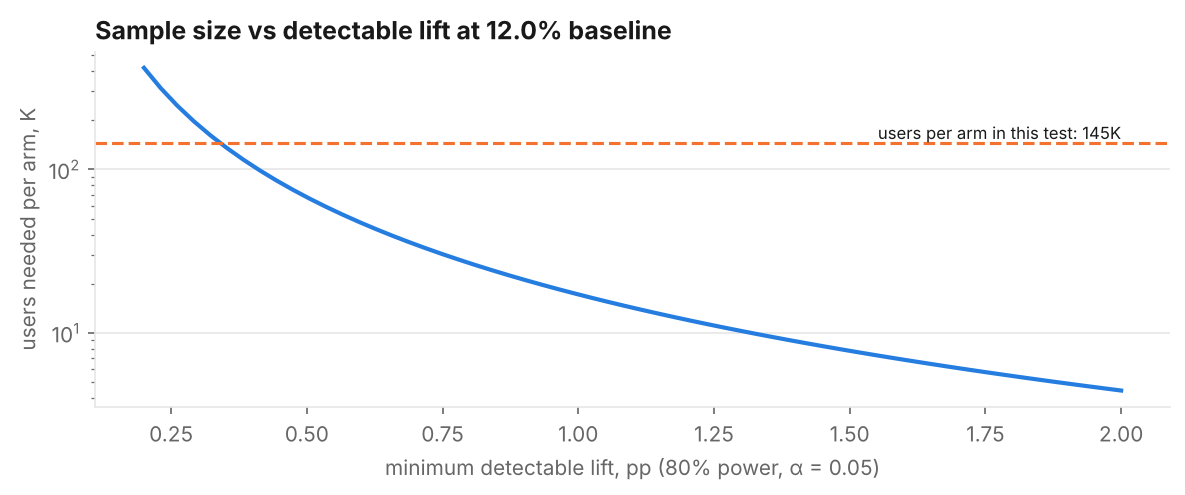

In [4]:
res = diff_in_proportions(df)
n_arm = min(res['n_control'], res['n_treatment'])
p0 = res['control_rate']
need = required_n_per_arm(p0, RULES.mde_abs)
mde_hat = achieved_mde(p0, n_arm)
print(f"baseline {p0:.2%} · need {need:,} users/arm to detect +0.5 pp · test has {n_arm:,} → detectable lift {mde_hat*100:.2f} pp")
fig_power(p0, n_arm, 'power_curve.png')
from IPython.display import Image; Image('power_curve.png')

## 3 · Result

control 12.04% vs treatment 11.88%
lift -0.16 pp (-1.3%) · 95% CI [-0.39, +0.08] pp · p = 0.190
P(new page better) = 9.5%


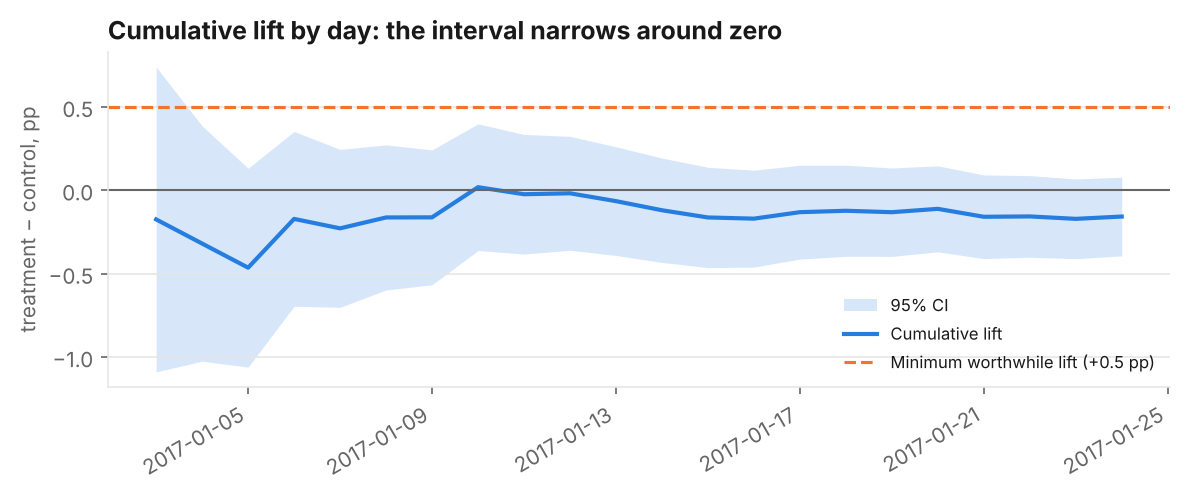

In [5]:
lo, hi = res['ci']
print(f"control {res['control_rate']:.2%} vs treatment {res['treatment_rate']:.2%}")
print(f"lift {res['diff']*100:+.2f} pp ({res['rel_lift']:+.1%}) · 95% CI [{lo*100:+.2f}, {hi*100:+.2f}] pp · p = {res['p_value']:.3f}")
print(f"P(new page better) = {prob_treatment_better(df):.1%}")
fig_cumulative(df, 'cumulative_lift.png'); Image('cumulative_lift.png')

## 4 · Does the effect differ by country?

In [6]:
country_interaction(df).round(3)

,coef,p_value
"treated:C(country, Treatment('US'))[T.CA]",-0.047,0.383
"treated:C(country, Treatment('US'))[T.UK]",0.031,0.238


## 5 · Decision

In [7]:
print(decide(res, mde_hat, srm_p))

DO NOT SHIP: the test was powered to detect +0.5 pp and the CI rules it out. Running longer would not change the decision.


**Do not ship.** The new page converts 0.16 pp *worse*. The 95% CI tops out at +0.08 pp, far below the +0.5 pp worth shipping. With 2× the users it needed, the test could detect lifts down to 0.34 pp, so running it longer wouldn't change the answer. No country behaves differently.